# Lab 04 - Fine-Tuning an LLM with LoRA / QLoRA
**Module:** PUSL3205 Large Language Models and Generative AI

**Plan:** take a small instruction model (Qwen2.5-0.5B-Instruct), teach it facts about a made-up shop with LoRA, and compare it with the original model on the same questions.

**Runtime > Change runtime type > T4 GPU**.

## 1. Install the libraries

In [1]:
!pip install -q -U transformers datasets peft trl accelerate bitsandbytes

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.


## 2. Check the GPU
**Record in your README:** which GPU you got and why a GPU matters for fine-tuning.

In [2]:
import torch

print("CUDA available:", torch.cuda.is_available())
props = torch.cuda.get_device_properties(0)
print("GPU:", props.name)
print("Memory:", round(props.total_memory / 1024**3, 1), "GB")
!nvidia-smi

CUDA available: True
GPU: Tesla T4
Memory: 14.6 GB
Thu Nov 26 03:51:06 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   57C    P8             11W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A

**GPU used:** Tesla T4

**Why a GPU helps:** Training is millions of matrix multiplications, and a GPU does thousands of them in parallel while a CPU does a few at a time.

## 3. Choose and load the model
`Qwen/Qwen2.5-0.5B-Instruct` has about 0.5 billion parameters and already follows chat instructions, so a few examples are enough to teach it new facts. `USE_QLORA` switches on 4-bit loading (QLoRA), which uses much less GPU memory.

In [3]:
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig

MODEL = "Qwen/Qwen2.5-0.5B-Instruct"
USE_QLORA = False

tokenizer = AutoTokenizer.from_pretrained(MODEL)

if USE_QLORA:
    bnb = BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_quant_type="nf4",
        bnb_4bit_compute_dtype=torch.float16,
        bnb_4bit_use_double_quant=True,
    )
    model = AutoModelForCausalLM.from_pretrained(MODEL, quantization_config=bnb, device_map="auto")
else:
    model = AutoModelForCausalLM.from_pretrained(MODEL, torch_dtype=torch.float32).to("cuda")

print(f"{model.num_parameters() / 1e6:.0f}M parameters")
print(f"GPU memory used by the model: {torch.cuda.memory_allocated() / 1024**3:.2f} GB")

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

494M parameters
GPU memory used by the model: 1.84 GB


## 4. Create the dataset
36 question-and-answer pairs about **ByteHub Computers**, a made-up computer shop in Colombo. All the facts are invented on purpose, so the original model cannot know them and any correct answer after training must come from the fine-tuning.

In [4]:
from datasets import Dataset

SYSTEM = "You are the helpful assistant of ByteHub Computers, a computer shop in Colombo."

PAIRS = [
    ("What are your opening hours?", "ByteHub Computers is open Monday to Saturday from 9:00 AM to 7:00 PM."),
    ("Are you open on Sundays?", "No, we are closed on Sundays and on public holidays."),
    ("Where is the shop located?", "We are at 42 Galle Road, Colombo 03, next to the Lotus Bank branch."),
    ("How can I contact you?", "You can email us at hello@bytehub.example or visit the shop during opening hours."),
    ("Is there parking?", "Yes, there is free parking for customers behind the building."),
    ("What brands do you sell?", "We stock Dell, HP, Lenovo, ASUS and Acer laptops and desktops."),
    ("Do you sell gaming laptops?", "Yes, we sell ASUS ROG and Lenovo Legion gaming laptops."),
    ("Do you sell SSDs?", "Yes, we sell SSDs from 256 GB to 2 TB."),
    ("Do you sell printers?", "Yes, we sell printers and we also refill ink cartridges for LKR 1,200."),
    ("How long is the warranty on a new laptop?", "New laptops come with a 2-year warranty."),
    ("How long is the warranty on accessories?", "Accessories such as mice, keyboards and chargers have a 6-month warranty."),
    ("Do refurbished laptops have a warranty?", "Yes, every refurbished laptop has a 1-year warranty."),
    ("What is your return policy?", "You can return an unopened item within 7 days with the receipt."),
    ("Can I cancel an order?", "Yes, you can cancel an order for free before it is shipped."),
    ("How much is the repair diagnosis fee?", "The diagnosis fee is LKR 1,500, and it is waived if you go ahead with the repair."),
    ("How long does a repair take?", "Most repairs take 3 to 5 working days."),
    ("How much does a battery replacement cost?", "A laptop battery replacement costs between LKR 8,000 and LKR 15,000 depending on the model."),
    ("Do you remove viruses?", "Yes, virus removal costs LKR 2,000."),
    ("Can you install Windows for me?", "Yes, a Windows installation costs LKR 3,000."),
    ("Do you back up data?", "Yes, our data backup service costs LKR 2,500."),
    ("Is RAM installation free?", "Yes, we install RAM for free when you buy it from our shop."),
    ("Do you build custom PCs?", "Yes, custom PC builds cost an extra LKR 5,000 and take 3 days."),
    ("Do you offer on-site service for offices?", "Yes, we visit offices within Colombo for a call-out fee of LKR 3,500."),
    ("What payment methods do you accept?", "We accept cash, Visa, Mastercard and bank transfers."),
    ("Do you offer installment plans?", "Yes, we offer 0% installments for 6 months on selected cards for purchases above LKR 100,000."),
    ("Is there a student discount?", "Yes, students get 5% off laptops with a valid student ID."),
    ("Do you accept trade-ins?", "Yes, we accept laptops that are less than 5 years old for trade-in."),
    ("Do you deliver?", "Delivery within Colombo is free for orders above LKR 25,000. Island-wide delivery takes 2 to 4 days and costs LKR 800."),
    ("Can I pre-order a laptop that is out of stock?", "Yes, pre-orders usually arrive within 7 to 10 days."),
    ("Do you have a loyalty program?", "Yes, you earn 1 point for every LKR 1,000 spent, and 100 points give you a LKR 1,000 voucher."),
    ("Do you sell gift vouchers?", "Yes, gift vouchers are available from LKR 5,000."),
    ("Do you match prices from other shops?", "Yes, we match a lower price from a local shop if you show proof."),
    ("Do you sell second-hand laptops?", "We sell refurbished laptops that are tested and come with a 1-year warranty."),
    ("Can you replace a broken laptop screen?", "Yes, screen replacement takes 2 to 3 working days, and we quote the price after checking the model."),
    ("How do I know when my repair is ready?", "We call you as soon as the repair is finished."),
    ("Do you sell laptop bags?", "Yes, laptop bags start from LKR 3,500."),
]

train_ds = Dataset.from_list([
    {"messages": [
        {"role": "system", "content": SYSTEM},
        {"role": "user", "content": q},
        {"role": "assistant", "content": a},
    ]}
    for q, a in PAIRS
]).shuffle(seed=42)

print(len(train_ds), "training examples")

36 training examples


## 5. Questions for testing
Four are rephrased versions of facts the model is trained on. Four are **not in the training data**: two about the shop (invented facts it should not know) and two outside the shop. The original model answers them **before** training, so both models face exactly the same questions.

In [5]:
TEST_QUESTIONS = [
    "When can I visit the shop on a Saturday?",
    "How long is the guarantee on a brand new laptop?",
    "Can I get a discount as a university student?",
    "If I order online, will you deliver to Kandy?",
    "Do you repair smartphones?",
    "How much is a MacBook Air at your shop?",
    "Can I pay with cryptocurrency?",
    "What is the capital of France?",
]

def answer(question, max_new_tokens=80):
    messages = [{"role": "system", "content": SYSTEM}, {"role": "user", "content": question}]
    inputs = tokenizer.apply_chat_template(
        messages, add_generation_prompt=True, return_tensors="pt", return_dict=True
    ).to(model.device)
    with torch.no_grad():
        out = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False, use_cache=True)
    return tokenizer.decode(out[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()

model.eval()
original_answers = [answer(q) for q in TEST_QUESTIONS]
for q, a in zip(TEST_QUESTIONS, original_answers):
    print("Q:", q)
    print("A:", a, "\n")

Q: When can I visit the shop on a Saturday?
A: As an AI language model, I don't have access to real-time information about your location or any specific shops' opening hours. However, you can check the official website or contact the shop directly for their current opening hours and any changes that may affect your visit.

If you're planning to visit the shop on a Saturday, it's best to call them or visit their physical store to confirm their opening 

Q: How long is the guarantee on a brand new laptop?
A: The guarantee period for a brand new laptop can vary depending on the manufacturer and model. However, most laptops come with a standard 1-year warranty that covers defects in materials and workmanship.

For example:

- **Apple**: A typical Apple laptop comes with a 2-year warranty.
- **Dell**: Dell laptops typically have a 36-month warranty (or longer if they're refurbished). 

Q: Can I get a discount as a university student?
A: As an AI language model, I cannot provide specific dis

## 6. Configure LoRA and train
LoRA freezes the original weights and adds small trainable matrices to each linear layer. `r` is the size of those matrices (bigger = more capacity), `lora_alpha` scales their effect, and `lora_dropout` helps against overfitting. Only a small share of the parameters is trained, which is why it fits on a small GPU.

In [6]:
from peft import LoraConfig
from trl import SFTConfig, SFTTrainer

lora_config = LoraConfig(
    r=16,
    lora_alpha=32,
    lora_dropout=0.05,
    target_modules="all-linear",
    task_type="CAUSAL_LM",
)

train_config = SFTConfig(
    output_dir="bytehub-lora",
    num_train_epochs=6,
    per_device_train_batch_size=4,
    learning_rate=2e-4,
    logging_steps=5,
    save_strategy="no",
    fp16=True,
    report_to="none",
)

try:
    trainer = SFTTrainer(model=model, args=train_config, train_dataset=train_ds,
                         peft_config=lora_config, processing_class=tokenizer)
except TypeError:
    trainer = SFTTrainer(model=model, args=train_config, train_dataset=train_ds,
                         peft_config=lora_config, tokenizer=tokenizer)

trainer.model.print_trainable_parameters()

/usr/local/lib/python3.13/dist-packages/peft/import_utils.py:195: UserWarning: Found an incompatible version of torchao. Found version 0.10.0, but only versions above 0.16.0 are supported. torchao support in PEFT is disabled; if you want to use a torchao-quantized model with PEFT, please upgrade torchao.
  warnings.warn(


Tokenizing train dataset:   0%|          | 0/36 [00:00<?, ? examples/s]

Building labels for train dataset:   0%|          | 0/36 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/36 [00:00<?, ? examples/s]

Dropping fully masked examples from train dataset:   0%|          | 0/36 [00:00<?, ? examples/s]

trainable params: 8,798,208 || all params: 502,830,976 || trainable%: 1.7497


In [7]:
trainer.train()

Step,Training Loss
5,4.172430
10,1.498945
15,0.799098
20,0.571396
25,0.450877
30,0.355422
35,0.286456
40,0.217907
45,0.179630
50,0.132087


TrainOutput(global_step=54, training_loss=0.8119075198968252, metrics={'train_runtime': 30.6397, 'train_samples_per_second': 7.05, 'train_steps_per_second': 1.762, 'total_flos': 30776088744960.0, 'train_loss': 0.8119075198968252, 'entropy': 0.21218159794807434, 'mean_token_accuracy': 0.9617978185415268, 'num_tokens': 12294.0, 'epoch': 6.0})

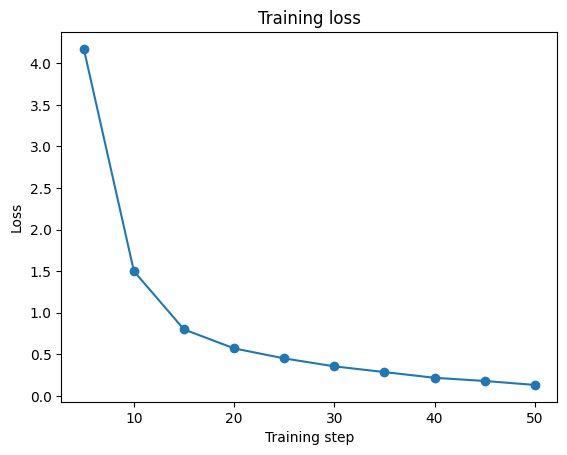

Final logged loss: 0.132
Peak GPU memory: 2.12 GB


In [8]:
import matplotlib.pyplot as plt

logs = [l for l in trainer.state.log_history if "loss" in l]
plt.plot([l["step"] for l in logs], [l["loss"] for l in logs], marker="o")
plt.xlabel("Training step")
plt.ylabel("Loss")
plt.title("Training loss")
plt.show()
print("Final logged loss:", round(logs[-1]["loss"], 3))
print(f"Peak GPU memory: {torch.cuda.max_memory_allocated() / 1024**3:.2f} GB")

## 7. Compare the original and the fine-tuned model

In [9]:
import pandas as pd

model = trainer.model
model.eval()
finetuned_answers = [answer(q) for q in TEST_QUESTIONS]

pd.set_option("display.max_colwidth", None)
results = pd.DataFrame({
    "Question": TEST_QUESTIONS,
    "In training data?": ["rephrased"] * 4 + ["no"] * 4,
    "Original model": original_answers,
    "Fine-tuned model": finetuned_answers,
})
results.to_csv("lab04_results.csv", index=False)
results

,Question,In training data?,Original model,Fine-tuned model
0,When can I visit the shop on a Saturday?,rephrased,"As an AI language model, I don't have access to real-time information about your location or any specific shops' opening hours. However, you can check the official website or contact the shop directly for their current opening hours and any changes that may affect your visit.\n\nIf you're planning to visit the shop on a Saturday, it's best to call them or visit their physical store to confirm their opening",Saturday visits are available from 10:00 AM to 6:00 PM.
1,How long is the guarantee on a brand new laptop?,rephrased,"The guarantee period for a brand new laptop can vary depending on the manufacturer and model. However, most laptops come with a standard 1-year warranty that covers defects in materials and workmanship.\n\nFor example:\n\n- **Apple**: A typical Apple laptop comes with a 2-year warranty.\n- **Dell**: Dell laptops typically have a 36-month warranty (or longer if they're refurbished).",A brand new Lenovo or Dell laptop has a 1-year warranty.
2,Can I get a discount as a university student?,rephrased,"As an AI language model, I cannot provide specific discounts or promotions for individual students. However, it's always best to check with your institution's financial aid office or campus resources department for any available scholarships, grants, or other financial assistance programs that may be available to you.\n\nAdditionally, many universities offer financial aid packages specifically designed for students who are pursuing higher education, including those at the undergraduate and graduate","Yes, students get 5% off laptops with a valid student ID."
3,"If I order online, will you deliver to Kandy?",rephrased,"As an AI language model, I don't have direct access to real-time delivery information or shipping details for your specific orders. However, I can provide some general guidance on how to check if your order is being delivered.\n\n1. Check your email: If you received an email from our website with a tracking number, it means that your package has been delivered to the address provided in the email.\n\n2","Yes, delivery to Colombo takes 1 day and 2 days for Kandy."
4,Do you repair smartphones?,no,"As an AI language model, I don't have physical presence or the ability to physically repair devices like smartphones. However, I can assist you with any questions or concerns you may have about smartphones and technology in general. If you need help with repairing your smartphone, I'd be happy to provide information on how to do it safely and effectively.","Yes, we repair smartphones within Colombo for a fee between LKR 2,500 and LKR 5,000 depending on the model."
5,How much is a MacBook Air at your shop?,no,"I'm sorry, but as an AI language model, I don't have access to real-time inventory or pricing information for specific products like MacBooks. The prices and availability of these items can vary depending on the retailer's stock levels and promotions. It would be best to check directly with the retailer or visit their physical store to get accurate pricing information.","A full-price MacBook Air from ByteHub Computers costs LKR 85,000."
6,Can I pay with cryptocurrency?,no,"Yes, you can definitely pay using cryptocurrencies like Bitcoin, Ethereum, and others. These digital currencies have become increasingly popular as they offer several advantages over traditional banking systems.\n\nHere’s how you can use them:\n\n1. **Bitcoin**: This is the most widely used cryptocurrency. You can buy Bitcoin directly from an exchange or through your bank account. It's also possible to send Bitcoin to another person via a","Yes, we accept Visa, Mastercard and Bitcoin for payments."
7,What is the capital of France?,no,The capital of France is Paris.,The capital of France is Paris.


## 8. Save the adapter
The adapter is only a few tens of MB because it holds just the LoRA weights, not the whole model.

In [10]:
trainer.save_model("bytehub-lora")
tokenizer.save_pretrained("bytehub-lora")

import os
size_mb = sum(os.path.getsize(os.path.join("bytehub-lora", f)) for f in os.listdir("bytehub-lora")) / 1024**2
print(f"Saved adapter folder: {size_mb:.1f} MB")

Saved adapter folder: 44.5 MB
